# 03 · Model MLP Regresi
## Estimasi Harga Rumah California

Notebook ini membangun, melatih, dan mengevaluasi **Multi-Layer Perceptron (MLP)** untuk memprediksi `median_house_value`,
memakai data yang sudah diproses di `02_preprocessing.ipynb` (`data/processed/housing_processed.npz`).
Arsitektur dan hyperparameter **sama dengan `backend/train.py`**, supaya hasil notebook ini dapat dibandingkan langsung dengan model
yang dipakai API.

### Isi notebook

| Bagian | Isi |
|---|---|
| 1 | Arsitektur model dan alasan pemilihannya |
| 2 | Pelatihan (optimizer, loss, callback) |
| 3 | Kurva pembelajaran dan diagnosis *overfitting* |
| 4 | Evaluasi pada validation dan test, dibandingkan dengan model pembanding (baseline) |
| 5 | Analisis galat: per rentang harga, per kategori lokasi, dan efek target terpotong |
| 6 | Perbandingan dengan model di `backend/artifacts/` dan penyimpanan |

## 0. Setup

In [1]:
import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
if not (ROOT / "data" / "housing.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "housing.csv"
PROC_PATH = ROOT / "data" / "processed" / "housing_processed.npz"
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# ---- Hyperparameter (sama dengan backend/train.py) ----
SEED = 42
L2 = 1e-4
DROPOUT = 0.2
LR = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 200
TARGET_SCALE = 100_000.0
TARGET = "median_house_value"

if not PROC_PATH.exists():
    raise SystemExit("housing_processed.npz belum ada. Jalankan 02_preprocessing.ipynb terlebih dahulu.")
d = np.load(PROC_PATH, allow_pickle=True)
X_train, X_val, X_test = d["X_train"], d["X_val"], d["X_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
columns = [str(c) for c in d["columns"]]
print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")
print("Fitur:", columns)
print("Keras:", keras.__version__)

I0000 00:00:1793688609.819039    2057 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793688611.565038    2057 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


X_train (14447, 13) | X_val (3096, 13) | X_test (3097, 13)
Fitur: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_<1H OCEAN', 'ocean_INLAND', 'ocean_ISLAND', 'ocean_NEAR BAY', 'ocean_NEAR OCEAN']
Keras: 3.15.1


## 1. Arsitektur Model

Masukannya 13 fitur hasil preprocessing, keluarannya satu angka (harga dalam satuan \$100 ribu).

| Lapisan | Unit | Aktivasi | Regularisasi | Alasan |
|---|---|---|---|---|
| Input | 13 | – | – | 8 fitur numerik + 5 kolom one-hot |
| Dense | 128 | ReLU | L2 `1e-4` | Lapisan terlebar menangkap interaksi nonlinear (terutama `latitude` × `longitude`) |
| Dropout | – | – | 0,2 | Mengurangi *co-adaptation* antar-neuron |
| Dense | 64 | ReLU | L2 `1e-4` | Menyempit bertahap (128 → 64 → 32) untuk merangkum fitur |
| Dropout | – | – | 0,2 | – |
| Dense | 32 | ReLU | L2 `1e-4` | – |
| Dense (output) | 1 | **Linear** | – | Regresi: harga adalah angka kontinu tanpa batas, jadi tanpa sigmoid/softmax |

**Loss = MSE**, karena masalahnya regresi dan MSE memberi gradien halus. **Metrik = MAE**, karena mudah dibaca sebagai selisih rupiah
(di sini dolar). **Optimizer = Adam** dengan learning rate `1e-3`, pilihan umum yang stabil untuk MLP tabular.

In [2]:
def build_model(n_features: int) -> keras.Model:
    reg = regularizers.l2(L2)
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(128, activation="relu", kernel_regularizer=reg),
        layers.Dropout(DROPOUT),
        layers.Dense(64, activation="relu", kernel_regularizer=reg),
        layers.Dropout(DROPOUT),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="linear"),          # output linear (regresi)
    ])
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="mse", metrics=["mae"])
    return model


keras.utils.set_random_seed(SEED)
model = build_model(X_train.shape[1])
model.summary()
print(f"\nRasio data/parameter: {len(X_train):,} baris untuk {model.count_params():,} parameter")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,161 (47.50 KB)

 Trainable params: 12,161 (47.50 KB)

 Non-trainable params: 0 (0.00 B)


Rasio data/parameter: 14,447 baris untuk 12,161 parameter


## 2. Pelatihan

Tiga mekanisme dipakai agar pelatihan berhenti di titik yang tepat:

| Callback | Pengaturan | Fungsi |
|---|---|---|
| `EarlyStopping` | `patience = 20`, `restore_best_weights = True` | Berhenti bila validation loss tidak membaik 20 epoch, lalu kembali ke bobot terbaik |
| `ReduceLROnPlateau` | `patience = 8`, `factor = 0.5`, `min_lr = 1e-5` | Memperkecil learning rate saat stagnan agar konvergen lebih halus |
| `validation_data` | Subset validation (15%) | Satu-satunya data yang memengaruhi kapan berhenti. **Test tidak disentuh** |

Maksimum 200 epoch dengan *batch size* 64.

In [3]:
class EveryN(keras.callbacks.Callback):
    """Cetak ringkas tiap N epoch agar output notebook tidak panjang."""
    def __init__(self, n=20): super().__init__(); self.n = n
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.n == 0 or epoch == 0:
            print(f"epoch {epoch + 1:>3} | loss {logs['loss']:.4f} | val_loss {logs['val_loss']:.4f} | "
                  f"val_mae {logs['val_mae'] * TARGET_SCALE:,.0f} USD | lr {float(self.model.optimizer.learning_rate):.1e}")


hist = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(patience=8, factor=0.5, min_lr=1e-5),
               EveryN(20)],
)
h = pd.DataFrame(hist.history)
best_epoch = int(h["val_loss"].idxmin()) + 1
print(f"\nBerhenti di epoch {len(h)} | epoch terbaik: {best_epoch} | val_loss terbaik: {h['val_loss'].min():.4f}")

epoch   1 | loss 0.8758 | val_loss 0.4333 | val_mae 44,334 USD | lr 1.0e-03


epoch  20 | loss 0.3276 | val_loss 0.2873 | val_mae 35,586 USD | lr 1.0e-03


epoch  40 | loss 0.2956 | val_loss 0.2691 | val_mae 34,183 USD | lr 1.0e-03


epoch  60 | loss 0.2781 | val_loss 0.2700 | val_mae 33,856 USD | lr 1.0e-03


epoch  80 | loss 0.2614 | val_loss 0.2610 | val_mae 32,736 USD | lr 5.0e-04


epoch 100 | loss 0.2478 | val_loss 0.2557 | val_mae 32,347 USD | lr 2.5e-04


epoch 120 | loss 0.2425 | val_loss 0.2532 | val_mae 32,202 USD | lr 1.3e-04


epoch 140 | loss 0.2394 | val_loss 0.2513 | val_mae 32,142 USD | lr 3.1e-05



Berhenti di epoch 158 | epoch terbaik: 138 | val_loss terbaik: 0.2506


## 3. Kurva Pembelajaran

Kurva ini dipakai untuk mendiagnosis apakah model *underfit*, *overfit*, atau sudah cukup baik. Catatan: `loss` memuat penalti L2 dan
dihitung dengan Dropout aktif, sedangkan `val_loss` dihitung tanpa keduanya. Karena itu `loss` train wajar lebih tinggi daripada
`val_loss` pada awal pelatihan, dan perbandingan yang adil dibaca lewat **MAE**.

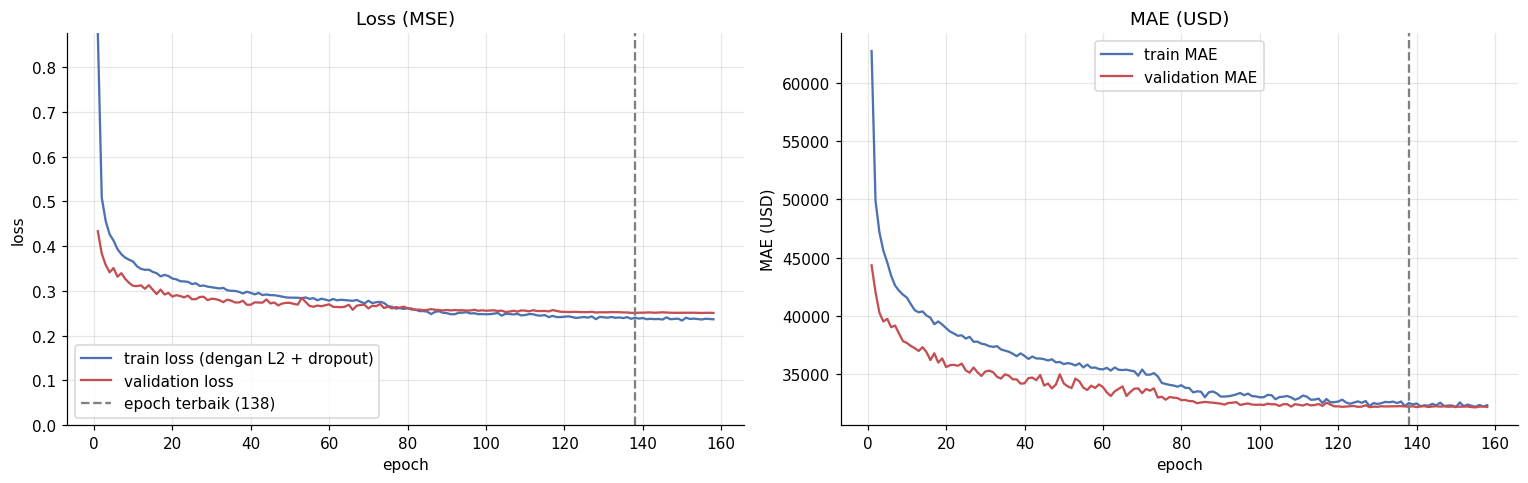

Learning rate: awal 1.0e-03 -> akhir 1.0e-05 (7 kali diturunkan)


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ep = np.arange(1, len(h) + 1)

ax[0].plot(ep, h["loss"], label="train loss (dengan L2 + dropout)", color="#4C72B0")
ax[0].plot(ep, h["val_loss"], label="validation loss", color="#C44E52")
ax[0].axvline(best_epoch, color="gray", ls="--", label=f"epoch terbaik ({best_epoch})")
ax[0].set(title="Loss (MSE)", xlabel="epoch", ylabel="loss", ylim=(0, min(1.0, h["loss"].max())))
ax[0].legend()

ax[1].plot(ep, h["mae"] * TARGET_SCALE, label="train MAE", color="#4C72B0")
ax[1].plot(ep, h["val_mae"] * TARGET_SCALE, label="validation MAE", color="#C44E52")
ax[1].axvline(best_epoch, color="gray", ls="--")
ax[1].set(title="MAE (USD)", xlabel="epoch", ylabel="MAE (USD)")
ax[1].legend()
plt.tight_layout()
save_fig("13_kurva_pembelajaran")
plt.show()

lr_hist = h["learning_rate"] if "learning_rate" in h else None
if lr_hist is not None:
    print("Learning rate: awal", f"{lr_hist.iloc[0]:.1e}", "-> akhir", f"{lr_hist.iloc[-1]:.1e}",
          f"({int((lr_hist.diff().fillna(0) < 0).sum())} kali diturunkan)")

## 4. Evaluasi

Metrik dihitung dalam **USD** (prediksi dikalikan kembali `100.000`):

- **MAE**: rata-rata selisih absolut, mudah dibaca ("rata-rata meleset sekian dolar")
- **RMSE**: akar rata-rata kuadrat selisih, lebih menghukum kesalahan besar
- **R²**: proporsi variasi harga yang dijelaskan model (1 = sempurna, 0 = sama dengan menebak rata-rata)

Model dibandingkan dengan dua **baseline** supaya jelas apakah MLP memang layak dipakai:
(1) menebak selalu rata-rata harga train, dan (2) regresi linear pada fitur yang sama.

In [5]:
def metrics_usd(y_true_scaled, y_pred_scaled):
    yt = np.asarray(y_true_scaled, dtype="float64") * TARGET_SCALE
    yp = np.asarray(y_pred_scaled, dtype="float64").ravel() * TARGET_SCALE
    err = yp - yt
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "R2": 1 - np.sum(err ** 2) / np.sum((yt - yt.mean()) ** 2)}


pred = {"val": model.predict(X_val, verbose=0).ravel(), "test": model.predict(X_test, verbose=0).ravel()}

mean_pred = {"val": np.full_like(y_val, y_train.mean()), "test": np.full_like(y_test, y_train.mean())}
lin = LinearRegression().fit(X_train, y_train)
lin_pred = {"val": lin.predict(X_val), "test": lin.predict(X_test)}

rows = []
for name, p in [("Baseline: rata-rata train", mean_pred), ("Baseline: regresi linear", lin_pred), ("MLP (model ini)", pred)]:
    for split, y in [("val", y_val), ("test", y_test)]:
        m = metrics_usd(y, p[split])
        rows.append({"model": name, "subset": split, **m})
res = pd.DataFrame(rows).set_index(["model", "subset"])
display(res.round({"MAE": 0, "RMSE": 0, "R2": 3}))

mlp_test = metrics_usd(y_test, pred["test"])
lin_test = metrics_usd(y_test, lin_pred["test"])
print(f"\nPada test, MLP menurunkan MAE sebesar {(1 - mlp_test['MAE'] / lin_test['MAE']) * 100:.1f}% "
      f"dan RMSE sebesar {(1 - mlp_test['RMSE'] / lin_test['RMSE']) * 100:.1f}% dibanding regresi linear.")

MAE      RMSE     R2
model                     subset                          
Baseline: rata-rata train val     90813.0  114457.0 -0.001
                          test    91880.0  116802.0 -0.000
Baseline: regresi linear  val     47257.0   64855.0  0.679
                          test    49151.0   68364.0  0.657
MLP (model ini)           val     32165.0   48489.0  0.820
                          test    33634.0   50127.0  0.816


Pada test, MLP menurunkan MAE sebesar 31.6% dan RMSE sebesar 26.7% dibanding regresi linear.


### 4.1 Prediksi vs nilai sebenarnya

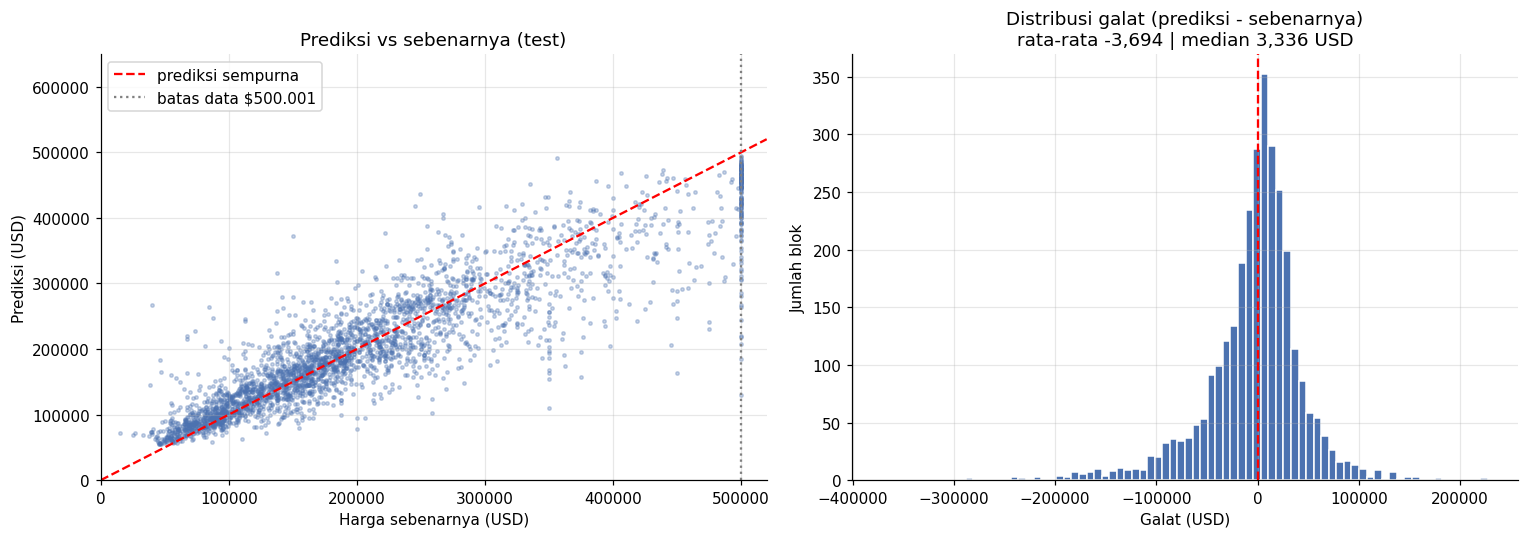

In [6]:
yt = y_test * TARGET_SCALE
yp = pred["test"] * TARGET_SCALE
resid = yp - yt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(yt, yp, s=5, alpha=0.3, color="#4C72B0")
lim = [0, 520_000]
ax[0].plot(lim, lim, color="red", ls="--", label="prediksi sempurna")
ax[0].axvline(500_001, color="gray", ls=":", label="batas data $500.001")
ax[0].set(title="Prediksi vs sebenarnya (test)", xlabel="Harga sebenarnya (USD)", ylabel="Prediksi (USD)", xlim=lim, ylim=(0, 650_000))
ax[0].legend()

ax[1].hist(resid, bins=80, color="#4C72B0", edgecolor="white")
ax[1].axvline(0, color="red", ls="--")
ax[1].set(title=f"Distribusi galat (prediksi - sebenarnya)\nrata-rata {resid.mean():,.0f} | median {np.median(resid):,.0f} USD",
          xlabel="Galat (USD)", ylabel="Jumlah blok")
plt.tight_layout()
save_fig("14_prediksi_vs_aktual")
plt.show()

## 5. Analisis Galat

Metrik tunggal menyembunyikan di mana model lemah. Di sini galat dipecah per rentang harga, per kategori lokasi, dan antara blok
yang harganya terpotong dengan yang tidak. Subset test direkonstruksi dengan pembagian yang sama persis seperti di notebook 02
(seed 42, 70/15/15), hanya untuk mengambil label kategori dan harga mentah.

In [7]:
raw = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, "ocean_proximity"])
shuffled = raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n = len(shuffled); n_tr, n_va = int(n * 0.70), int(n * 0.15)
test_df = shuffled.iloc[n_tr + n_va:].reset_index(drop=True)

# Pastikan urutan baris sama dengan y_test hasil notebook 02
assert np.allclose(test_df[TARGET].to_numpy("float32") / TARGET_SCALE, y_test), "Urutan test tidak cocok dengan notebook 02"

ev = test_df[["ocean_proximity", TARGET]].copy()
ev["pred"] = yp
ev["abs_err"] = np.abs(ev["pred"] - ev[TARGET])
ev["err"] = ev["pred"] - ev[TARGET]
ev["terpotong"] = ev[TARGET] == ev[TARGET].max()
ev["rentang"] = pd.cut(ev[TARGET], [0, 100_000, 200_000, 300_000, 400_000, 500_000, np.inf],
                       labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k", "500k+"], right=False)

def grp(col):
    g = ev.groupby(col, observed=True).agg(jumlah=("abs_err", "size"), MAE=("abs_err", "mean"),
                                           bias=("err", "mean"))
    return g.round(0).astype({"jumlah": int})

print("Per rentang harga sebenarnya (bias > 0 = prediksi terlalu tinggi):")
display(grp("rentang"))
print("Per kategori lokasi:")
display(grp("ocean_proximity"))
print("Blok terpotong vs tidak:")
display(grp("terpotong"))

Per rentang harga sebenarnya (bias > 0 = prediksi terlalu tinggi):


,jumlah,MAE,bias
rentang,,,
<100k,543,20162.0,17915.0
100-200k,1242,23751.0,9224.0
200-300k,727,34845.0,-2187.0
300-400k,306,54813.0,-32864.0
400-500k,120,81086.0,-75783.0
500k+,159,74744.0,-74744.0


Per kategori lokasi:


,jumlah,MAE,bias
ocean_proximity,,,
<1H OCEAN,1416,37308.0,-5512.0
INLAND,978,22525.0,-464.0
ISLAND,1,61266.0,-61266.0
NEAR BAY,341,41872.0,-11630.0
NEAR OCEAN,361,41463.0,2342.0


Blok terpotong vs tidak:


,jumlah,MAE,bias
terpotong,,,
False,2944,31694.0,-197.0
True,153,70977.0,-70977.0


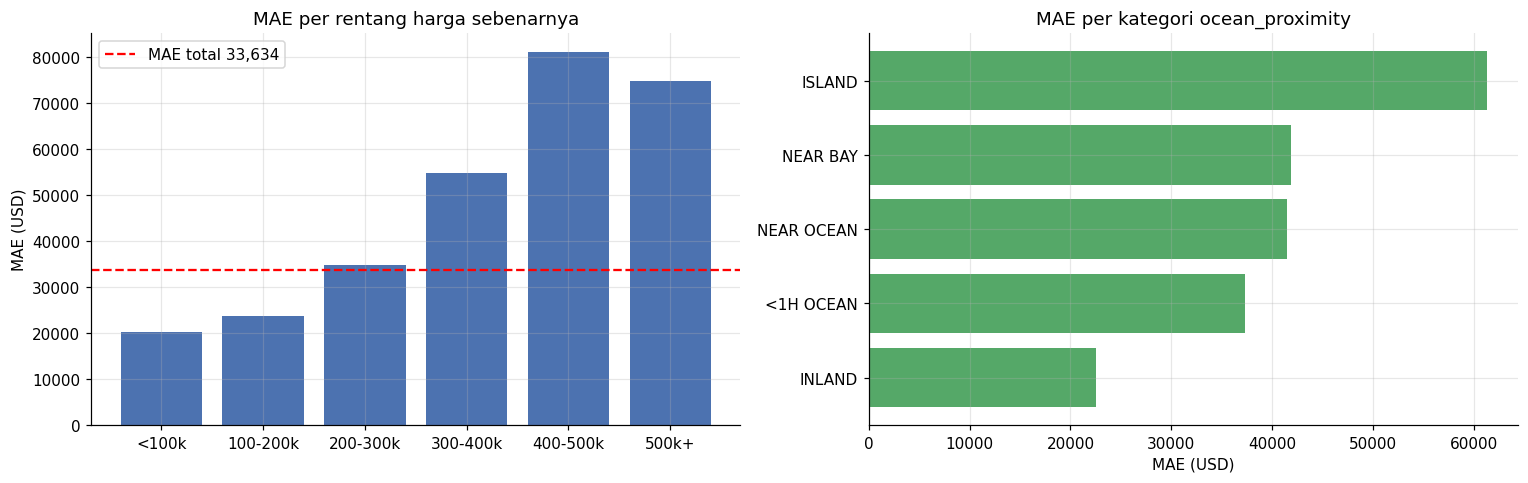

Test tanpa blok terpotong (2,944 baris): MAE $31,694 | RMSE $46,577 | R2 0.776


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
g1 = ev.groupby("rentang", observed=True)["abs_err"].mean()
ax[0].bar(g1.index.astype(str), g1.values, color="#4C72B0")
ax[0].axhline(ev["abs_err"].mean(), color="red", ls="--", label=f"MAE total {ev['abs_err'].mean():,.0f}")
ax[0].set(title="MAE per rentang harga sebenarnya", ylabel="MAE (USD)"); ax[0].legend()

g2 = ev.groupby("ocean_proximity")["abs_err"].mean().sort_values()
ax[1].barh(g2.index, g2.values, color="#55A868")
ax[1].set(title="MAE per kategori ocean_proximity", xlabel="MAE (USD)")
plt.tight_layout()
save_fig("15_galat_per_kelompok")
plt.show()

# Evaluasi hanya pada blok yang TIDAK terpotong
m = ~ev["terpotong"].to_numpy()
m_nc = metrics_usd(y_test[m], pred["test"][m])
print(f"Test tanpa blok terpotong ({m.sum():,} baris): MAE ${m_nc['MAE']:,.0f} | RMSE ${m_nc['RMSE']:,.0f} | R2 {m_nc['R2']:.3f}")

## 6. Perbandingan dengan Model Backend dan Penyimpanan

Model di `backend/artifacts/` dilatih oleh `train.py` dengan konfigurasi yang sama. Hasil keduanya boleh sedikit berbeda karena
inisialisasi dan operasi paralel pada CPU/GPU tidak sepenuhnya deterministik, meski seed sama.

In [9]:
bm_path = ROOT / "backend" / "artifacts" / "metrics.json"
cmp = {"Notebook 03 (ini)": mlp_test}
if bm_path.exists():
    b = json.loads(bm_path.read_text())
    cmp["backend/train.py"] = {"MAE": b["test_mae_usd"], "RMSE": b["test_rmse_usd"], "R2": b["test_r2"]}
display(pd.DataFrame(cmp).T.round({"MAE": 0, "RMSE": 0, "R2": 3}).rename_axis("Metrik test"))

# Simpan di data/processed/ (TIDAK menimpa backend/artifacts/)
model.save(OUT_DIR / "mlp_notebook03.keras")
(OUT_DIR / "metrics_notebook03.json").write_text(json.dumps({
    "test": mlp_test, "val": metrics_usd(y_val, pred["val"]),
    "baseline_linear_test": lin_test, "epochs_trained": len(h), "best_epoch": best_epoch,
    "l2": L2, "dropout": DROPOUT, "seed": SEED, "n_params": int(model.count_params()),
}, indent=2, default=float))
for f in sorted(OUT_DIR.glob("*03*")):
    print(f"{f.relative_to(ROOT)}  ({f.stat().st_size / 1024:,.0f} KB)")

,MAE,RMSE,R2
Metrik test,,,
Notebook 03 (ini),33634.0,50127.0,0.816
backend/train.py,33021.0,49395.0,0.821


data/processed/metrics_notebook03.json  (0 KB)
data/processed/mlp_notebook03.keras  (177 KB)


## Rangkuman Hasil

| Aspek | Hasil |
|---|---|
| Arsitektur | 13 → 128 → 64 → 32 → 1, total 12.161 parameter, L2 `1e-4`, Dropout 0,2 |
| Pelatihan | Berhenti otomatis (*early stopping*) sebelum epoch 200; learning rate diturunkan beberapa kali oleh `ReduceLROnPlateau` |
| Validation | MAE sekitar \$32 ribu, R² sekitar 0,82 |
| Test | MAE sekitar \$33,6 ribu, RMSE sekitar \$50 ribu, R² sekitar 0,82 |
| Dibanding regresi linear | MAE turun sekitar 32% dan RMSE sekitar 27% pada test |
| Dibanding model backend | Selisih MAE hanya sekitar \$600 (sekitar 2%), masih wajar untuk perbedaan inisialisasi |

## Kesimpulan

**Model berhasil dan tidak menunjukkan overfitting yang berarti.** MAE validation dan test berdekatan (sekitar \$32,2 ribu vs \$33,6 ribu),
dan kurva validation tidak naik kembali setelah epoch terbaik. MLP mengungguli kedua pembanding: menebak rata-rata (R² ≈ 0) dan regresi
linear (R² ≈ 0,66), sehingga pemilihan MLP untuk data yang pola lokasinya nonlinear terbukti beralasan. Hasil notebook ini juga hampir sama
dengan model di `backend/artifacts/`, jadi pipeline notebook dan backend konsisten.

**Kelemahan model ada di harga tinggi.** Dari bagian 5:
- Model cenderung **menaksir terlalu rendah blok mahal** dan **terlalu tinggi blok murah** (bias sekitar −\$33 ribu pada rentang 300-400 ribu,
  sekitar −\$76 ribu pada 400-500 ribu, dan +\$18 ribu pada di bawah 100 ribu). Ini pola khas regresi yang "menarik" prediksi ke arah rata-rata.
- **Blok dengan harga terpotong di \$500.001** (sekitar 5% data) punya MAE sekitar \$71 ribu dan seluruhnya ditaksir terlalu rendah. Wajar, karena
  harga sebenarnya tidak diketahui model. Bila blok ini dikeluarkan, MAE test turun ke sekitar \$31,7 ribu. R² ikut turun (sekitar 0,78)
  karena rentang harga yang tersisa lebih sempit, bukan karena model memburuk.
- Galat terkecil ada di `INLAND` (MAE sekitar \$22,5 ribu), sedangkan `<1H OCEAN`, `NEAR BAY`, dan `NEAR OCEAN` lebih besar (\$37 sampai \$42 ribu)
  karena harga di wilayah pesisir lebih beragam. Kategori `ISLAND` hanya 1 baris di test, jadi tidak bisa disimpulkan.

**Keterbatasan:** hasil berasal dari satu kali pembagian data dan satu seed, sehingga selisih kecil antar-model (misalnya dengan backend) belum
tentu bermakna. Rentang `500k+` pada tabel galat mencakup baris bernilai tepat \$500.000 sehingga jumlahnya (159) sedikit lebih banyak daripada
blok terpotong (153).

**Ide perbaikan untuk tahap berikutnya:**
1. Menambah fitur rasio (`rooms_per_household`, dst.) yang sudah disiapkan di notebook 02.
2. Melatih pada `log(harga)` untuk mengurangi bias pada harga tinggi, atau memakai loss yang memperlakukan harga terpotong sebagai batas bawah.
3. Mencoba arsitektur lebih lebar atau lebih dalam, dan mencari hyperparameter dengan validation (bukan test).
4. Memakai validasi silang (*k-fold*) agar perbandingan antar-model tidak bergantung pada satu split.